# Econ 4850 · Economic Analysis with Python
## Lecture 4: Pandas Basics
Geoffrey Kam, Washington University in St. Louis · g.kam@wustl.edu · Spring 2025

**What you'll learn**

- The two core pandas data structures, `Series` and `DataFrame`, and how to create, select, rename and plot them.
- How to reshape panel data with hierarchical indexes, `stack`/`unstack`, and `pivot`/`pivot_table`.
- How to aggregate, transform and filter data with `agg`, `apply`, boolean selection and `query`.
- A short digression on bootstrapping a confidence interval with pandas.

## Introduction and Motivation

Economic research often involves:

- **Data import and cleaning:** raw data come in various formats and usually need substantial cleaning.
- **Data manipulation and transformation:** extracting meaningful subsets, filtering, and aggregating data to test economic theories.
- **Time-series analysis:** many economic indicators are measured over time, so efficient date and time manipulation is critical.
- **Visualization and reporting:** conveying results clearly through plots and summary tables.

Pandas provides high-level data structures, the `Series` (one-dimensional) and the `DataFrame` (two-dimensional), that are well suited to these tasks.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

Check which version of pandas you have installed. Some behavior differs across major versions (for example, the default of `str.replace` used below changed in pandas 2.0).

In [2]:
pd.__version__

'2.2.3'

## Data Structures

I mostly follow [QuantEcon](https://datascience.quantecon.org/pandas/intro.html) in this lecture.

### Series

A `Series` is a single column of data, with a row label (the index) for each observation.

<Axes: title={'center': 'Unemployment in the US'}>

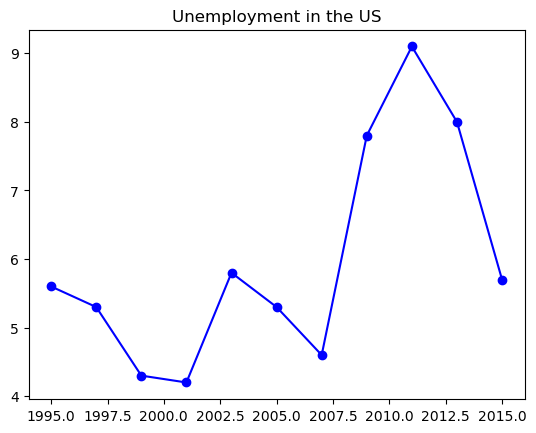

In [3]:
# Create a Series from a list
values = [5.6, 5.3, 4.3, 4.2, 5.8, 5.3, 4.6, 7.8, 9.1, 8., 5.7]
years = list(range(1995, 2017, 2))

unemp = pd.Series(data=values, index=years, name="Unemployment")

unemp.plot(title="Unemployment in the US", color="blue", marker="o", linestyle="-")

Useful attributes and methods to explore on your own:

- `.index` and `.values` return the row labels and the data.
- `.head()`, `.tail()` and `.sample()` show the first rows, the last rows, or a random draw of rows. With `replace=True`, `.sample()` draws with replacement, which we use for bootstrapping at the end of this lecture.
- `.loc` selects by label and `.iloc` by position. (`.iat` also exists; it is good to know, but you will rarely use it.)
- `.plot()` draws a quick plot.

### Basic Operations

Arithmetic on a `Series` is applied element by element.

In [4]:
print(unemp)
unemp + unemp

1995    5.6
1997    5.3
1999    4.3
2001    4.2
2003    5.8
2005    5.3
2007    4.6
2009    7.8
2011    9.1
2013    8.0
2015    5.7
Name: Unemployment, dtype: float64


1995    11.2
1997    10.6
1999     8.6
2001     8.4
2003    11.6
2005    10.6
2007     9.2
2009    15.6
2011    18.2
2013    16.0
2015    11.4
Name: Unemployment, dtype: float64

<Axes: title={'center': 'Economic Indicator'}>

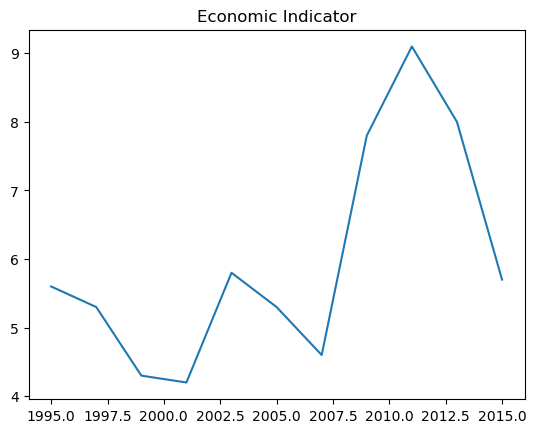

In [5]:
unemp.plot(title="Economic Indicator")

### DataFrame

We can think of a `DataFrame` as several `Series` placed side by side as columns.

In [6]:
data = {
    "NorthEast": [5.9, 5.6, 4.4, 3.8, 5.8, 4.9, 4.3, 7.1, 8.3, 7.9, 5.7],
    "MidWest": [4.5, 4.3, 3.6, 4., 5.7, 5.7, 4.9, 8.1, 8.7, 7.4, 5.1],
    "South": [5.3, 5.2, 4.2, 4., 5.7, 5.2, 4.3, 7.6, 9.1, 7.4, 5.5],
    "West": [6.6, 6., 5.2, 4.6, 6.5, 5.5, 4.5, 8.6, 10.7, 8.5, 6.1],
    "National": [5.6, 5.3, 4.3, 4.2, 5.8, 5.3, 4.6, 7.8, 9.1, 8., 5.7],
}

unemp_region = pd.DataFrame(data, index=years)

# Also try .describe() and .dtypes
unemp_region.corr()

,NorthEast,MidWest,South,West,National
NorthEast,1.000000,0.875654,0.964415,0.967875,0.976016
MidWest,0.875654,1.000000,0.951379,0.900638,0.952389
South,0.964415,0.951379,1.000000,0.987259,0.995030
West,0.967875,0.900638,0.987259,1.000000,0.981308
National,0.976016,0.952389,0.995030,0.981308,1.000000


Select rows and columns by label with `.loc[rows, columns]`. Note that label slices such as `2001:2005` include both endpoints.

      NorthEast  MidWest  South  West  National
1995        5.9      4.5    5.3   6.6       5.6
1997        5.6      4.3    5.2   6.0       5.3
1999        4.4      3.6    4.2   5.2       4.3


<Axes: title={'center': 'Unemployment in the US by Region'}>

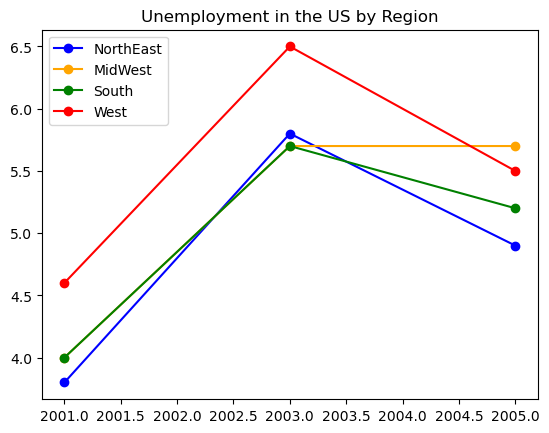

In [7]:
print(unemp_region.head(3))

unemp_region.loc[2001:2005, ["NorthEast", "MidWest", "South", "West"]].plot(
    title="Unemployment in the US by Region",
    color=["blue", "orange", "green", "red"],
    marker="o",
    linestyle="-",
)

`.T` transposes the `DataFrame`: rows become columns and columns become rows.

In [8]:
print(unemp_region.head())
unemp_region.T

      NorthEast  MidWest  South  West  National
1995        5.9      4.5    5.3   6.6       5.6
1997        5.6      4.3    5.2   6.0       5.3
1999        4.4      3.6    4.2   5.2       4.3
2001        3.8      4.0    4.0   4.6       4.2
2003        5.8      5.7    5.7   6.5       5.8


,1995,1997,1999,2001,2003,2005,2007,2009,2011,2013,2015
NorthEast,5.9,5.6,4.4,3.8,5.8,4.9,4.3,7.1,8.3,7.9,5.7
MidWest,4.5,4.3,3.6,4.0,5.7,5.7,4.9,8.1,8.7,7.4,5.1
South,5.3,5.2,4.2,4.0,5.7,5.2,4.3,7.6,9.1,7.4,5.5
West,6.6,6.0,5.2,4.6,6.5,5.5,4.5,8.6,10.7,8.5,6.1
National,5.6,5.3,4.3,4.2,5.8,5.3,4.6,7.8,9.1,8.0,5.7


### Creating New Columns

In [9]:
print(unemp_region.head())
unemp_region["UnweightedMean"] = (unemp_region["NorthEast"]
                                  + unemp_region["MidWest"]
                                  + unemp_region["South"]
                                  + unemp_region["West"]) / 4
unemp_region

      NorthEast  MidWest  South  West  National
1995        5.9      4.5    5.3   6.6       5.6
1997        5.6      4.3    5.2   6.0       5.3
1999        4.4      3.6    4.2   5.2       4.3
2001        3.8      4.0    4.0   4.6       4.2
2003        5.8      5.7    5.7   6.5       5.8


,NorthEast,MidWest,South,West,National,UnweightedMean
1995,5.9,4.5,5.3,6.6,5.6,5.575
1997,5.6,4.3,5.2,6.0,5.3,5.275
1999,4.4,3.6,4.2,5.2,4.3,4.350
2001,3.8,4.0,4.0,4.6,4.2,4.100
2003,5.8,5.7,5.7,6.5,5.8,5.925
2005,4.9,5.7,5.2,5.5,5.3,5.325
2007,4.3,4.9,4.3,4.5,4.6,4.500
2009,7.1,8.1,7.6,8.6,7.8,7.850
2011,8.3,8.7,9.1,10.7,9.1,9.200
2013,7.9,7.4,7.4,8.5,8.0,7.800


### Renaming Columns

`rename` returns a *new* `DataFrame` and leaves the original unchanged. To keep the result, either assign it to a variable or pass `inplace=True`.

In [10]:
names = {"NorthEast": "NE",
         "MidWest": "MW",
         "South": "S",
         "West": "W"}

# Option 1: returns a renamed copy; unemp_region itself is unchanged
temp = unemp_region.rename(columns=names)

# Option 2: modify unemp_region directly
unemp_region.rename(columns=names, inplace=True)
unemp_region

,NE,MW,S,W,National,UnweightedMean
1995,5.9,4.5,5.3,6.6,5.6,5.575
1997,5.6,4.3,5.2,6.0,5.3,5.275
1999,4.4,3.6,4.2,5.2,4.3,4.350
2001,3.8,4.0,4.0,4.6,4.2,4.100
2003,5.8,5.7,5.7,6.5,5.8,5.925
2005,4.9,5.7,5.2,5.5,5.3,5.325
2007,4.3,4.9,4.3,4.5,4.6,4.500
2009,7.1,8.1,7.6,8.6,7.8,7.850
2011,8.3,8.7,9.1,10.7,9.1,9.200
2013,7.9,7.4,7.4,8.5,8.0,7.800


## Basic Functionality

We now load a larger panel of monthly unemployment data by US state. `read_csv` is probably the most frequently used pandas function (it is certainly the most popular one on Kaggle). Loading the file takes a couple of seconds.

In [11]:
url = "https://datascience.quantecon.org/assets/data/state_unemployment.csv"

unemp_raw = pd.read_csv(url, parse_dates=["Date"])
unemp_raw.head()

,Date,state,LaborForce,UnemploymentRate
0,2000-01-01,Alabama,2142945.0,4.7
1,2000-01-01,Alaska,319059.0,6.3
2,2000-01-01,Arizona,2499980.0,4.1
3,2000-01-01,Arkansas,1264619.0,4.4
4,2000-01-01,California,16680246.0,5.0


In [12]:
unemp_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10800 entries, 0 to 10799
Data columns (total 4 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Date              10800 non-null  datetime64[ns]
 1   state             10800 non-null  object        
 2   LaborForce        10800 non-null  float64       
 3   UnemploymentRate  10800 non-null  float64       
dtypes: datetime64[ns](1), float64(2), object(1)
memory usage: 337.6+ KB


## Reshaping the Data

### Hierarchical Index

A `DataFrame` can have several levels of row labels. Here each row is identified by a state *and* a date.

In [13]:
unemp_all = unemp_raw.set_index(["state", "Date"])
unemp_all.head(3)

,,LaborForce,UnemploymentRate
state,Date,,
Alabama,2000-01-01,2142945.0,4.7
Alaska,2000-01-01,319059.0,6.3
Arizona,2000-01-01,2499980.0,4.1


`melt` converts a wide table into a long one (one row per variable-value pair) and drops the index.

In [14]:
unemp_all.melt()

,variable,value
0,LaborForce,2142945.0
1,LaborForce,319059.0
2,LaborForce,2499980.0
3,LaborForce,1264619.0
4,LaborForce,16680246.0
...,...,...
21595,UnemploymentRate,3.6
21596,UnemploymentRate,4.7
21597,UnemploymentRate,5.4
21598,UnemploymentRate,3.2


### Index Logic

Select all rows for one or more values of the outer level, or a single row by giving a value for every level.

In [15]:
unemp_all.loc[["Alabama", "Alaska"]]

LaborForce  UnemploymentRate
state   Date                                    
Alabama 2000-01-01   2142945.0               4.7
        2000-02-01   2142351.0               4.7
        2000-03-01   2140697.0               4.6
        2000-04-01   2138178.0               4.6
        2000-05-01   2135307.0               4.5
...                        ...               ...
Alaska  2017-08-01    362802.0               7.2
        2017-09-01    362660.0               7.2
        2017-10-01    362514.0               7.2
        2017-11-01    362458.0               7.2
        2017-12-01    362473.0               7.2

[432 rows x 2 columns]

In [16]:
unemp_all.loc[("Alabama", "2000-01-01")]

LaborForce          2142945.0
UnemploymentRate          4.7
Name: (Alabama, 2000-01-01 00:00:00), dtype: float64

### Stack

If you do not care about this hierarchical structure, you can simply stack it. `stack` moves the column labels (the level closest to the values) into the row index as its innermost level.

In [17]:
print(unemp_all.T)
unemp_all.T.stack()

state               Alabama     Alaska    Arizona   Arkansas  California  \
Date             2000-01-01 2000-01-01 2000-01-01 2000-01-01  2000-01-01   
LaborForce        2142945.0   319059.0  2499980.0  1264619.0  16680246.0   
UnemploymentRate        4.7        6.3        4.1        4.4         5.0   

state              Colorado Connecticut   Delaware    Florida    Georgia  ...  \
Date             2000-01-01  2000-01-01 2000-01-01 2000-01-01 2000-01-01  ...   
LaborForce        2354671.0   1768421.0   405052.0  7766891.0  4198288.0  ...   
UnemploymentRate        2.8         2.8        3.5        3.7        3.7  ...   

state            South Dakota  Tennessee       Texas       Utah    Vermont  \
Date               2017-12-01 2017-12-01  2017-12-01 2017-12-01 2017-12-01   
LaborForce           456271.0  3218569.0  13591013.0  1573889.0   344870.0   
UnemploymentRate          3.4        3.3         4.0        3.2        2.9   

state              Virginia Washington West Virginia  Wis

<ipython-input>:2: FutureWarning: The previous implementation of stack is deprecated and will be removed in a future version of pandas. See the What's New notes for pandas 2.1.0 for details. Specify future_stack=True to adopt the new implementation and silence this warning.
  unemp_all.T.stack()


state                          Alabama    Alaska    Arizona   Arkansas  \
                 Date                                                    
LaborForce       2000-01-01  2142945.0  319059.0  2499980.0  1264619.0   
                 2000-02-01  2142351.0  319147.0  2502752.0  1265218.0   
                 2000-03-01  2140697.0  319291.0  2503992.0  1264912.0   
                 2000-04-01  2138178.0  319477.0  2503989.0  1263822.0   
                 2000-05-01  2135307.0  319659.0  2503461.0  1262136.0   
...                                ...       ...        ...        ...   
UnemploymentRate 2017-08-01        4.0       7.2        4.7        3.7   
                 2017-09-01        3.9       7.2        4.7        3.7   
                 2017-10-01        3.8       7.2        4.7        3.7   
                 2017-11-01        3.8       7.2        4.7        3.7   
                 2017-12-01        3.8       7.2        4.7        3.7   

state                        California   Colorado  Connecticut  Delaware  \
                 Date                                                       
LaborForce       2000-01-01  16680246.0  2354671.0    1768421.0  405052.0   
                 2000-02-01  16732795.0  2356780.0    1769105.0  406611.0   
                 2000-03-01  16778343.0  2357991.0    1768741.0  408297.0   
                 2000-04-01  16815943.0  2358321.0    1767722.0  410055.0   
                 2000-05-01  16844925.0  2357978.0    1766345.0  411779.0   
...                                 ...        ...          ...       ...   
UnemploymentRate 2017-08-01         4.6        2.9          4.5       4.6   
                 2017-09-01         4.5        3.0          4.5       4.5   
                 2017-10-01         4.5        3.0          4.5       4.5   
                 2017-11-01         4.5        3.0          4.5       4.5   
                 2017-12-01         4.5        3.0          4.5       4.5   

state                          Florida    Georgia  ...  South Dakota  \
                 Date                              ...                 
LaborForce       2000-01-01  7766891.0  4198288.0  ...      409296.0   
                 2000-02-01  7789735.0  4205995.0  ...      409464.0   
                 2000-03-01  7807619.0  4213192.0  ...      409423.0   
                 2000-04-01  7821650.0  4219262.0  ...      409173.0   
                 2000-05-01  7833369.0  4223636.0  ...      408782.0   
...                                ...        ...  ...           ...   
UnemploymentRate 2017-08-01        4.0        4.5  ...           3.4   
                 2017-09-01        3.9        4.5  ...           3.4   
                 2017-10-01        3.9        4.5  ...           3.4   
                 2017-11-01        3.9        4.5  ...           3.4   
                 2017-12-01        3.9        4.5  ...           3.4   

state                        Tennessee       Texas       Utah   Vermont  \
                 Date                                                     
LaborForce       2000-01-01  2852337.0  10352120.0  1128581.0  329193.0   
                 2000-02-01  2852381.0  10363975.0  1130836.0  329551.0   
                 2000-03-01  2851026.0  10368180.0  1133369.0  329949.0   
                 2000-04-01  2848175.0  10366277.0  1135920.0  330367.0   
                 2000-05-01  2844087.0  10360899.0  1138332.0  330799.0   
...                                ...         ...        ...       ...   
UnemploymentRate 2017-08-01        3.4         4.0        3.2       3.0   
                 2017-09-01        3.3         4.0        3.2       2.9   
                 2017-10-01        3.3         3.9        3.2       2.9   
                 2017-11-01        3.3         3.9        3.2       2.9   
                 2017-12-01        3.3         4.0        3.2       2.9   

state                         Virginia  Washington  West Virginia  Wisconsin  \
                 Date                     

Of course, you can also `unstack`, which moves an index level into the columns.

In [18]:
unemp_all.unstack(level="state").loc[:, "UnemploymentRate"]

state,Alabama,Alaska,Arizona,Arkansas,California,Colorado,Connecticut,Delaware,Florida,Georgia,...,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin,Wyoming
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-01,4.7,6.3,4.1,4.4,5.0,2.8,2.8,3.5,3.7,3.7,...,2.4,3.7,4.6,3.1,2.7,2.6,4.9,5.8,3.2,4.1
2000-02-01,4.7,6.3,4.1,4.3,5.0,2.8,2.7,3.6,3.7,3.6,...,2.4,3.7,4.6,3.1,2.6,2.5,4.9,5.6,3.2,3.9
2000-03-01,4.6,6.3,4.0,4.3,5.0,2.7,2.6,3.6,3.7,3.6,...,2.4,3.8,4.5,3.1,2.6,2.4,5.0,5.5,3.3,3.9
2000-04-01,4.6,6.3,4.0,4.3,5.1,2.7,2.5,3.7,3.7,3.7,...,2.4,3.8,4.4,3.1,2.7,2.4,5.0,5.4,3.4,3.8
2000-05-01,4.5,6.3,4.0,4.2,5.1,2.7,2.4,3.7,3.7,3.7,...,2.4,3.9,4.3,3.2,2.7,2.3,5.1,5.4,3.5,3.8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-08-01,4.0,7.2,4.7,3.7,4.6,2.9,4.5,4.6,4.0,4.5,...,3.4,3.4,4.0,3.2,3.0,3.7,4.8,5.2,3.3,4.1
2017-09-01,3.9,7.2,4.7,3.7,4.5,3.0,4.5,4.5,3.9,4.5,...,3.4,3.3,4.0,3.2,2.9,3.6,4.7,5.3,3.3,4.1
2017-10-01,3.8,7.2,4.7,3.7,4.5,3.0,4.5,4.5,3.9,4.5,...,3.4,3.3,3.9,3.2,2.9,3.6,4.7,5.4,3.2,4.2


## String Methods

Textual analysis is increasingly popular in economics, so it is worth knowing the basics. The `.str` accessor applies string methods to every element of a column.

In [19]:
unemp_all.head()

,,LaborForce,UnemploymentRate
state,Date,,
Alabama,2000-01-01,2142945.0,4.7
Alaska,2000-01-01,319059.0,6.3
Arizona,2000-01-01,2499980.0,4.1
Arkansas,2000-01-01,1264619.0,4.4
California,2000-01-01,16680246.0,5.0


In [20]:
unemp_state = unemp_all.reset_index("state")
unemp_state

,state,LaborForce,UnemploymentRate
Date,,,
2000-01-01,Alabama,2142945.0,4.7
2000-01-01,Alaska,319059.0,6.3
2000-01-01,Arizona,2499980.0,4.1
2000-01-01,Arkansas,1264619.0,4.4
2000-01-01,California,16680246.0,5.0
...,...,...,...
2017-12-01,Virginia,4318483.0,3.6
2017-12-01,Washington,3754871.0,4.7
2017-12-01,West Virginia,781852.0,5.4


In [21]:
unemp_state["state"].str.contains("A")

Date
2000-01-01     True
2000-01-01     True
2000-01-01     True
2000-01-01     True
2000-01-01    False
              ...  
2017-12-01    False
2017-12-01    False
2017-12-01    False
2017-12-01    False
2017-12-01    False
Name: state, Length: 10800, dtype: bool

In [22]:
unemp_state[unemp_state["state"].str.contains("A")]

,state,LaborForce,UnemploymentRate
Date,,,
2000-01-01,Alabama,2142945.0,4.7
2000-01-01,Alaska,319059.0,6.3
2000-01-01,Arizona,2499980.0,4.1
2000-01-01,Arkansas,1264619.0,4.4
2000-02-01,Alabama,2142351.0,4.7
...,...,...,...
2017-11-01,Arkansas,1357161.0,3.7
2017-12-01,Alabama,2163554.0,3.8
2017-12-01,Alaska,362473.0,7.2


String methods can do almost anything you need. For example, we can split email addresses into usernames and domains:

In [23]:
df = pd.DataFrame({"Email": ["alice@example.com", "bob@work.net", "charlie@school.edu"]})
print(df)

df["Username"] = df["Email"].str.split("@").str[0]  # extract username
df["Domain"] = df["Email"].str.split("@").str[1]  # extract domain

print(df)

                Email
0   alice@example.com
1        bob@work.net
2  charlie@school.edu
                Email Username       Domain
0   alice@example.com    alice  example.com
1        bob@work.net      bob     work.net
2  charlie@school.edu  charlie   school.edu


Regular expressions (RegEx) are even more powerful: they can describe almost any text pattern (you could, for example, extract all the vowels from a string). Here are a few common ones.

In [24]:
df = pd.DataFrame({"Text": ["apple123", "banana456", "cherry789", "date012"]})
df

,Text
0,apple123
1,banana456
2,cherry789
3,date012


In [25]:
# Flag rows containing at least one digit
df["Has_Digits"] = df["Text"].str.contains(r"\d")

print(df)

        Text  Has_Digits
0   apple123        True
1  banana456        True
2  cherry789        True
3    date012        True


In [26]:
# Extract the first run of digits
df["Numbers"] = df["Text"].str.extract(r"(\d+)")

print(df)

        Text  Has_Digits Numbers
0   apple123        True     123
1  banana456        True     456
2  cherry789        True     789
3    date012        True     012


In [27]:
# Remove all digits (regex=True is required in pandas 2.0 and later)
df["Text_Cleaned"] = df["Text"].str.replace(r"\d+", "", regex=True)
print(df)

        Text  Has_Digits Numbers Text_Cleaned
0   apple123        True     123        apple
1  banana456        True     456       banana
2  cherry789        True     789       cherry
3    date012        True     012         date


I just want you to know that these tools exist. When you need a specific pattern, you can look it up or ask ChatGPT.

## More on Indexes and Reshaping

### `pd.IndexSlice`

`pd.IndexSlice` selects across all values of an outer index level, for example every state on a given date. Note that you must include the column selection (`:`) even when you want all columns.

In [28]:
print(unemp_all.head())
unemp_all.loc[pd.IndexSlice[:, "2000-01-01"], :]

                       LaborForce  UnemploymentRate
state      Date                                    
Alabama    2000-01-01   2142945.0               4.7
Alaska     2000-01-01    319059.0               6.3
Arizona    2000-01-01   2499980.0               4.1
Arkansas   2000-01-01   1264619.0               4.4
California 2000-01-01  16680246.0               5.0


,,LaborForce,UnemploymentRate
state,Date,,
Alabama,2000-01-01,2142945.0,4.7
Alaska,2000-01-01,319059.0,6.3
Arizona,2000-01-01,2499980.0,4.1
Arkansas,2000-01-01,1264619.0,4.4
California,2000-01-01,16680246.0,5.0
Colorado,2000-01-01,2354671.0,2.8
Connecticut,2000-01-01,1768421.0,2.8
Delaware,2000-01-01,405052.0,3.5
Florida,2000-01-01,7766891.0,3.7


### Reset Index

`reset_index` moves one or more levels of the index back into the `DataFrame` as columns. If no index is left, pandas uses the default index `range(df.shape[0])`.

In [29]:
unemp_all.reset_index()

,state,Date,LaborForce,UnemploymentRate
0,Alabama,2000-01-01,2142945.0,4.7
1,Alaska,2000-01-01,319059.0,6.3
2,Arizona,2000-01-01,2499980.0,4.1
3,Arkansas,2000-01-01,1264619.0,4.4
4,California,2000-01-01,16680246.0,5.0
...,...,...,...,...
10795,Virginia,2017-12-01,4318483.0,3.6
10796,Washington,2017-12-01,3754871.0,4.7
10797,West Virginia,2017-12-01,781852.0,5.4
10798,Wisconsin,2017-12-01,3158257.0,3.2


### Pivot Table

`pivot_table` reshapes long data into a wide table. Here we put dates in the rows and states in the columns.

In [30]:
print(unemp_raw.head())

unemp_all = (
    unemp_raw
    .reset_index()  # reset the index
    .pivot_table(index="Date", columns="state", values="UnemploymentRate")  # one column per state
)
unemp_all.head()

        Date       state  LaborForce  UnemploymentRate
0 2000-01-01     Alabama   2142945.0               4.7
1 2000-01-01      Alaska    319059.0               6.3
2 2000-01-01     Arizona   2499980.0               4.1
3 2000-01-01    Arkansas   1264619.0               4.4
4 2000-01-01  California  16680246.0               5.0


state,Alabama,Alaska,Arizona,Arkansas,California,Colorado,Connecticut,Delaware,Florida,Georgia,...,South Dakota,Tennessee,Texas,Utah,Vermont,Virginia,Washington,West Virginia,Wisconsin,Wyoming
Date,,,,,,,,,,,,,,,,,,,,,
2000-01-01,4.7,6.3,4.1,4.4,5.0,2.8,2.8,3.5,3.7,3.7,...,2.4,3.7,4.6,3.1,2.7,2.6,4.9,5.8,3.2,4.1
2000-02-01,4.7,6.3,4.1,4.3,5.0,2.8,2.7,3.6,3.7,3.6,...,2.4,3.7,4.6,3.1,2.6,2.5,4.9,5.6,3.2,3.9
2000-03-01,4.6,6.3,4.0,4.3,5.0,2.7,2.6,3.6,3.7,3.6,...,2.4,3.8,4.5,3.1,2.6,2.4,5.0,5.5,3.3,3.9
2000-04-01,4.6,6.3,4.0,4.3,5.1,2.7,2.5,3.7,3.7,3.7,...,2.4,3.8,4.4,3.1,2.7,2.4,5.0,5.4,3.4,3.8
2000-05-01,4.5,6.3,4.0,4.2,5.1,2.7,2.4,3.7,3.7,3.7,...,2.4,3.9,4.3,3.2,2.7,2.3,5.1,5.4,3.5,3.8


Note that, unlike `pivot`, `pivot_table` can handle duplicated index pairs. We demonstrate this at the end of the lecture.

## Trick: Quickly Selecting Columns

Print the column names, then copy and paste the ones you need into a list.

In [31]:
pd.set_option("display.max_columns", 500)
unemp_all.columns

Index(['Alabama', 'Alaska', 'Arizona', 'Arkansas', 'California', 'Colorado',
       'Connecticut', 'Delaware', 'Florida', 'Georgia', 'Hawaii', 'Idaho',
       'Illinois', 'Indiana', 'Iowa', 'Kansas', 'Kentucky', 'Louisiana',
       'Maine', 'Maryland', 'Massachusetts', 'Michigan', 'Minnesota',
       'Mississippi', 'Missouri', 'Montana', 'Nebraska', 'Nevada',
       'New Hampshire', 'New Mexico', 'New York', 'New jersey',
       'North Carolina', 'North Dakota', 'Ohio', 'Oklahoma', 'Oregon',
       'Pennsylvania', 'Rhode island', 'South Carolina', 'South Dakota',
       'Tennessee', 'Texas', 'Utah', 'Vermont', 'Virginia', 'Washington',
       'West Virginia', 'Wisconsin', 'Wyoming'],
      dtype='object', name='state')

In [32]:
# Names are copied exactly as they appear in the data
states = ["Massachusetts", "Michigan", "Minnesota",
          "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada",
          "New Hampshire", "New Mexico", "New York", "New jersey",
          "North Carolina", "North Dakota"]

<Axes: title={'center': 'Unemployment Rate by State'}, xlabel='Date'>

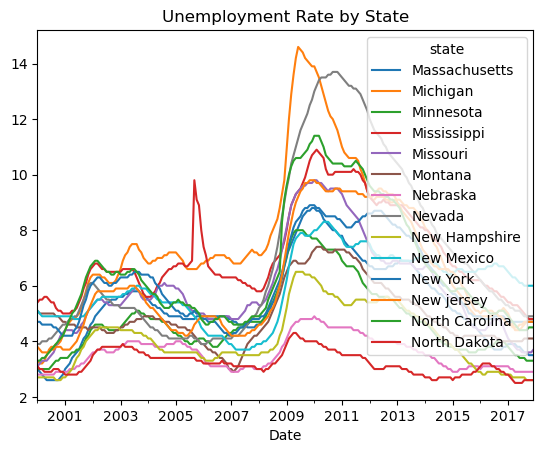

In [33]:
unemp_all[states].plot(title="Unemployment Rate by State")

In [34]:
unemp = unemp_all[states]
unemp.head()

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
Date,,,,,,,,,,,,,,
2000-01-01,3.0,3.3,3.0,5.4,3.1,5.1,2.8,3.9,2.7,5.1,4.7,3.8,3.3,3.1
2000-02-01,2.9,3.2,3.0,5.5,3.2,5.0,2.8,3.9,2.7,5.0,4.7,3.7,3.3,3.0
2000-03-01,2.8,3.2,3.0,5.5,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,3.0
2000-04-01,2.7,3.3,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,2.9
2000-05-01,2.6,3.5,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.5,2.9


## Dates in pandas

Because we passed `parse_dates=["Date"]` to `read_csv`, the index is already a `DatetimeIndex`. (Otherwise, convert it with `pd.to_datetime`.) This lets us select a period with date strings.

In [35]:
# Data corresponding to a period
unemp.loc["01/01/2000":"06/01/2000"]

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
Date,,,,,,,,,,,,,,
2000-01-01,3.0,3.3,3.0,5.4,3.1,5.1,2.8,3.9,2.7,5.1,4.7,3.8,3.3,3.1
2000-02-01,2.9,3.2,3.0,5.5,3.2,5.0,2.8,3.9,2.7,5.0,4.7,3.7,3.3,3.0
2000-03-01,2.8,3.2,3.0,5.5,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,3.0
2000-04-01,2.7,3.3,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,2.9
2000-05-01,2.6,3.5,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.5,2.9
2000-06-01,2.6,3.7,3.0,5.5,3.4,5.0,2.8,4.1,2.7,4.9,4.6,3.6,3.6,2.9


## Aggregation

You can compute almost any summary statistic down the rows, giving one result per column (`axis=0`, the default), or across the columns, giving one result per row (`axis=1`).

In [36]:
print(unemp)
unemp.max(axis=0)

state       Massachusetts  Michigan  Minnesota  Mississippi  Missouri  \
Date                                                                    
2000-01-01            3.0       3.3        3.0          5.4       3.1   
2000-02-01            2.9       3.2        3.0          5.5       3.2   
2000-03-01            2.8       3.2        3.0          5.5       3.3   
2000-04-01            2.7       3.3        3.0          5.6       3.3   
2000-05-01            2.6       3.5        3.0          5.6       3.3   
...                   ...       ...        ...          ...       ...   
2017-08-01            3.6       4.6        3.4          5.0       3.6   
2017-09-01            3.6       4.7        3.3          4.9       3.6   
2017-10-01            3.5       4.7        3.3          4.8       3.6   
2017-11-01            3.5       4.7        3.3          4.8       3.6   
2017-12-01            3.5       4.7        3.3          4.8       3.7   

state       Montana  Nebraska  Nevada  New Hampshi

state
Massachusetts      8.8
Michigan          14.6
Minnesota          8.0
Mississippi       10.9
Missouri           9.8
Montana            7.4
Nebraska           4.9
Nevada            13.7
New Hampshire      6.5
New Mexico         8.3
New York           8.9
New jersey         9.8
North Carolina    11.4
North Dakota       4.3
dtype: float64

In [37]:
# Along each row: the state with the highest unemployment rate in each month
unemp.idxmax(axis=1)

Date
2000-01-01    Mississippi
2000-02-01    Mississippi
2000-03-01    Mississippi
2000-04-01    Mississippi
2000-05-01    Mississippi
                 ...     
2017-08-01     New Mexico
2017-09-01     New Mexico
2017-10-01     New Mexico
2017-11-01     New Mexico
2017-12-01     New Mexico
Length: 216, dtype: object

### Custom Aggregation

In [38]:
def high_or_low(s):
    """
    Take a pandas Series and return "High" if its mean is at least 6.5
    and "Low" if its mean is below 6.5.
    """
    if s.mean() < 6.5:
        out = "Low"
    else:
        out = "High"

    return out

In [39]:
# Applied to each column (default axis=0)
unemp.agg(high_or_low)

state
Massachusetts      Low
Michigan          High
Minnesota          Low
Mississippi       High
Missouri           Low
Montana            Low
Nebraska           Low
Nevada            High
New Hampshire      Low
New Mexico         Low
New York           Low
New jersey         Low
North Carolina    High
North Dakota       Low
dtype: object

In [40]:
# Multiple aggregations at once
unemp.agg(["mean", "std", high_or_low])

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
mean,5.421759,7.492593,4.799537,7.161111,5.944907,4.965741,3.580093,7.1,4.128704,5.971759,6.102315,6.158333,6.616204,3.226852
std,1.513794,2.611004,1.294802,1.650501,1.706805,1.119689,0.583432,3.162748,1.081734,1.240213,1.51444,1.996841,2.20181,0.417213
high_or_low,Low,High,Low,High,Low,Low,Low,High,Low,Low,Low,Low,High,Low


## Transformation

Some methods return an object of the same shape, for example the percentage change from one period to the next. Missing values can be handled with `dropna()`, `fillna()` or `interpolate()`.

In [41]:
print(unemp.head())
unemp.pct_change().dropna()

state       Massachusetts  Michigan  Minnesota  Mississippi  Missouri  \
Date                                                                    
2000-01-01            3.0       3.3        3.0          5.4       3.1   
2000-02-01            2.9       3.2        3.0          5.5       3.2   
2000-03-01            2.8       3.2        3.0          5.5       3.3   
2000-04-01            2.7       3.3        3.0          5.6       3.3   
2000-05-01            2.6       3.5        3.0          5.6       3.3   

state       Montana  Nebraska  Nevada  New Hampshire  New Mexico  New York  \
Date                                                                         
2000-01-01      5.1       2.8     3.9            2.7         5.1       4.7   
2000-02-01      5.0       2.8     3.9            2.7         5.0       4.7   
2000-03-01      5.0       2.8     4.0            2.7         4.9       4.6   
2000-04-01      5.0       2.8     4.0            2.7         4.9       4.6   
2000-05-01      5.0 

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
Date,,,,,,,,,,,,,,
2000-02-01,-0.033333,-0.030303,0.000000,0.018519,0.032258,-0.019608,0.0,0.000000,0.000000,-0.019608,0.000000,-0.026316,0.000000,-0.032258
2000-03-01,-0.034483,0.000000,0.000000,0.000000,0.031250,0.000000,0.0,0.025641,0.000000,-0.020000,-0.021277,-0.027027,0.030303,0.000000
2000-04-01,-0.035714,0.031250,0.000000,0.018182,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-0.033333
2000-05-01,-0.037037,0.060606,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.029412,0.000000
2000-06-01,0.000000,0.057143,0.000000,-0.017857,0.030303,0.000000,0.0,0.025000,0.000000,0.000000,0.000000,0.000000,0.028571,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-08-01,-0.027027,0.022222,0.000000,-0.019608,0.000000,0.025000,0.0,-0.020000,0.000000,-0.016393,0.000000,0.021739,0.000000,0.040000
2017-09-01,0.000000,0.021739,-0.029412,-0.020000,0.000000,0.000000,0.0,0.000000,-0.037037,0.000000,0.000000,0.000000,0.000000,0.000000
2017-10-01,-0.027778,0.000000,0.000000,-0.020408,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.022727,0.000000


### Apply

`apply` runs a function on each column (or, with `axis=1`, each row).

In [42]:
# Step 1: write the Series transformation we would like to use
def standardize_data(x):
    """
    Transform the data in a Series to have mean 0 and standard deviation 1.
    """
    mu = x.mean()
    std = x.std()

    return (x - mu) / std

In [43]:
# Step 2: apply our function with the apply method
print(unemp)
std_unemp = unemp.apply(standardize_data)
std_unemp.head()

state       Massachusetts  Michigan  Minnesota  Mississippi  Missouri  \
Date                                                                    
2000-01-01            3.0       3.3        3.0          5.4       3.1   
2000-02-01            2.9       3.2        3.0          5.5       3.2   
2000-03-01            2.8       3.2        3.0          5.5       3.3   
2000-04-01            2.7       3.3        3.0          5.6       3.3   
2000-05-01            2.6       3.5        3.0          5.6       3.3   
...                   ...       ...        ...          ...       ...   
2017-08-01            3.6       4.6        3.4          5.0       3.6   
2017-09-01            3.6       4.7        3.3          4.9       3.6   
2017-10-01            3.5       4.7        3.3          4.8       3.6   
2017-11-01            3.5       4.7        3.3          4.8       3.6   
2017-12-01            3.5       4.7        3.3          4.8       3.7   

state       Montana  Nebraska  Nevada  New Hampshi

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
Date,,,,,,,,,,,,,,
2000-01-01,-1.599795,-1.605740,-1.389817,-1.067016,-1.666803,0.119908,-1.337076,-1.011778,-1.320753,-0.702911,-0.925962,-1.181032,-1.506126,-0.304046
2000-02-01,-1.665854,-1.644039,-1.389817,-1.006428,-1.608214,0.030597,-1.337076,-1.011778,-1.320753,-0.783542,-0.925962,-1.231111,-1.506126,-0.543732
2000-03-01,-1.731913,-1.644039,-1.389817,-1.006428,-1.549625,0.030597,-1.337076,-0.980160,-1.320753,-0.864173,-0.991993,-1.281191,-1.460709,-0.543732
2000-04-01,-1.797973,-1.605740,-1.389817,-0.945840,-1.549625,0.030597,-1.337076,-0.980160,-1.320753,-0.864173,-0.991993,-1.281191,-1.460709,-0.783418
2000-05-01,-1.864032,-1.529141,-1.389817,-0.945840,-1.549625,0.030597,-1.337076,-0.980160,-1.320753,-0.864173,-0.991993,-1.281191,-1.415292,-0.783418


In [44]:
# Take the absolute value of every element
abs_std_unemp = std_unemp.abs()

abs_std_unemp.head()

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
Date,,,,,,,,,,,,,,
2000-01-01,1.599795,1.605740,1.389817,1.067016,1.666803,0.119908,1.337076,1.011778,1.320753,0.702911,0.925962,1.181032,1.506126,0.304046
2000-02-01,1.665854,1.644039,1.389817,1.006428,1.608214,0.030597,1.337076,1.011778,1.320753,0.783542,0.925962,1.231111,1.506126,0.543732
2000-03-01,1.731913,1.644039,1.389817,1.006428,1.549625,0.030597,1.337076,0.980160,1.320753,0.864173,0.991993,1.281191,1.460709,0.543732
2000-04-01,1.797973,1.605740,1.389817,0.945840,1.549625,0.030597,1.337076,0.980160,1.320753,0.864173,0.991993,1.281191,1.460709,0.783418
2000-05-01,1.864032,1.529141,1.389817,0.945840,1.549625,0.030597,1.337076,0.980160,1.320753,0.864173,0.991993,1.281191,1.415292,0.783418


In [45]:
abs_std_unemp.idxmax()

state
Massachusetts    2009-12-01
Michigan         2009-06-01
Minnesota        2009-05-01
Mississippi      2010-02-01
Missouri         2010-01-01
Montana          2010-02-01
Nebraska         2010-01-01
Nevada           2010-09-01
New Hampshire    2009-05-01
New Mexico       2010-05-01
New York         2009-11-01
New jersey       2009-11-01
North Carolina   2010-01-01
North Dakota     2009-04-01
dtype: datetime64[ns]

### What Is the Difference Between `.map()`, `.apply()` and `.agg()`?

- `.map()` is designed for element-wise transformations of a `Series` or `DataFrame`.
- `.apply()` operates on an entire row (`axis=1`) or column (`axis=0`).
- `.agg()` (aggregation) is used to summarize data (e.g., summing or averaging).

## Boolean Selection

In [46]:
# A short name for the data we filter below
unemp_small = unemp
unemp_small

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
Date,,,,,,,,,,,,,,
2000-01-01,3.0,3.3,3.0,5.4,3.1,5.1,2.8,3.9,2.7,5.1,4.7,3.8,3.3,3.1
2000-02-01,2.9,3.2,3.0,5.5,3.2,5.0,2.8,3.9,2.7,5.0,4.7,3.7,3.3,3.0
2000-03-01,2.8,3.2,3.0,5.5,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,3.0
2000-04-01,2.7,3.3,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,2.9
2000-05-01,2.6,3.5,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.5,2.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-08-01,3.6,4.6,3.4,5.0,3.6,4.1,2.9,4.9,2.7,6.0,4.7,4.7,4.4,2.6
2017-09-01,3.6,4.7,3.3,4.9,3.6,4.1,2.9,4.9,2.6,6.0,4.7,4.7,4.4,2.6
2017-10-01,3.5,4.7,3.3,4.8,3.6,4.1,2.9,4.9,2.6,6.0,4.7,4.7,4.5,2.6


In [47]:
bool_index = (unemp_small["Missouri"] > unemp_small["Massachusetts"]) | (unemp_small["Minnesota"] > 4.5)

bool_index

Date
2000-01-01     True
2000-02-01     True
2000-03-01     True
2000-04-01     True
2000-05-01     True
              ...  
2017-08-01    False
2017-09-01    False
2017-10-01     True
2017-11-01     True
2017-12-01     True
Length: 216, dtype: bool

In [48]:
unemp_small.loc[bool_index]

state,Massachusetts,Michigan,Minnesota,Mississippi,Missouri,Montana,Nebraska,Nevada,New Hampshire,New Mexico,New York,New jersey,North Carolina,North Dakota
Date,,,,,,,,,,,,,,
2000-01-01,3.0,3.3,3.0,5.4,3.1,5.1,2.8,3.9,2.7,5.1,4.7,3.8,3.3,3.1
2000-02-01,2.9,3.2,3.0,5.5,3.2,5.0,2.8,3.9,2.7,5.0,4.7,3.7,3.3,3.0
2000-03-01,2.8,3.2,3.0,5.5,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,3.0
2000-04-01,2.7,3.3,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.4,2.9
2000-05-01,2.6,3.5,3.0,5.6,3.3,5.0,2.8,4.0,2.7,4.9,4.6,3.6,3.5,2.9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2017-01-01,3.9,5.0,3.8,5.4,4.1,4.0,3.1,5.3,2.8,6.5,4.7,4.6,4.9,2.8
2017-02-01,3.9,4.8,3.7,5.4,4.0,4.0,3.0,5.2,2.8,6.4,4.7,4.6,4.8,2.7
2017-10-01,3.5,4.7,3.3,4.8,3.6,4.1,2.9,4.9,2.6,6.0,4.7,4.7,4.5,2.6


### `query`

The `.query()` method filters a `DataFrame` using expressive, SQL-like conditions written as a string. Boolean indexing is explicit, but it can make your code unnecessarily long; `query` is often easier to read.

First, check that `query` gives the same result as the boolean selection above:

In [49]:
unemp_small.query("Missouri > Massachusetts | Minnesota > 4.5").equals(unemp_small.loc[bool_index])

True

Use `@` to refer to a Python variable inside the query string:

In [50]:
bound = 4.5
unemp_small.query("Missouri > Massachusetts | Minnesota > @bound").equals(unemp_small.loc[bool_index])

True

You can also do arithmetic with such variables inside the query:

In [51]:
bound = 4.5 * 2
unemp_small.query("Missouri > Massachusetts | Minnesota > @bound * 0.5").equals(unemp_small.loc[bool_index])

True

## Exercise (5 minutes)

Using the state unemployment data, find the mean and standard deviation of the labor force for every state over the sample period, and plot them as a bar chart.

One possible solution. First, put the data back into a panel structure:

In [52]:
unemp_all = unemp_raw.set_index(["state", "Date"])
print(unemp_all.head())

                       LaborForce  UnemploymentRate
state      Date                                    
Alabama    2000-01-01   2142945.0               4.7
Alaska     2000-01-01    319059.0               6.3
Arizona    2000-01-01   2499980.0               4.1
Arkansas   2000-01-01   1264619.0               4.4
California 2000-01-01  16680246.0               5.0


<Axes: >

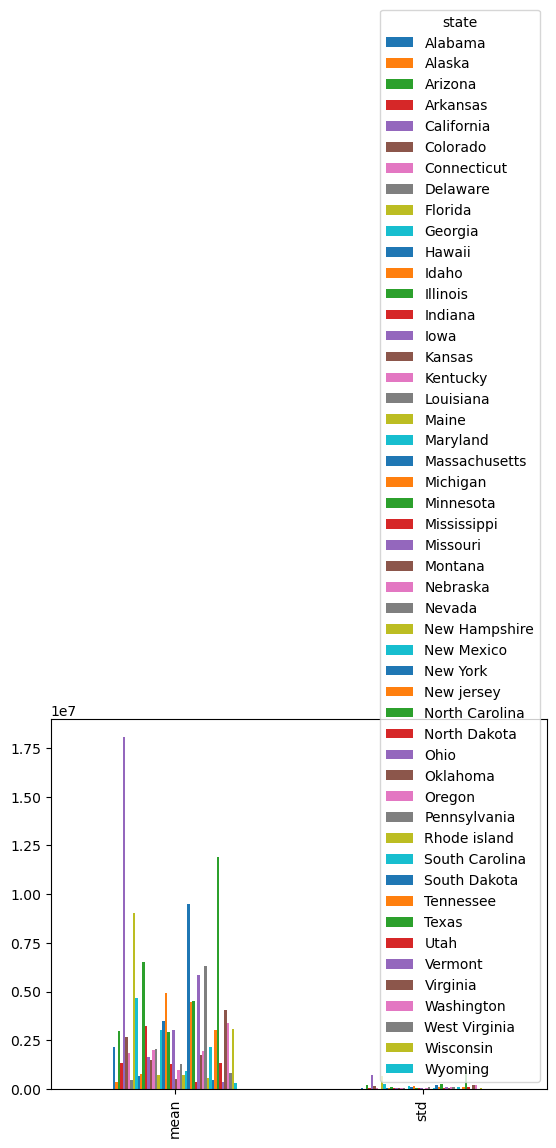

In [53]:
unemp_all.T.loc["LaborForce"].unstack(level="state").agg(["mean", "std"]).plot(kind="bar")

## `pivot` vs. `pivot_table`

In [54]:
url = "https://datascience.quantecon.org/assets/data/bball.csv"
bball = pd.read_csv(url)
bball.info()

bball

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Year      9 non-null      int64  
 1   Player    9 non-null      object 
 2   Team      9 non-null      object 
 3   TeamName  9 non-null      object 
 4   Games     9 non-null      int64  
 5   Pts       9 non-null      float64
 6   Assist    9 non-null      float64
 7   Rebound   9 non-null      float64
dtypes: float64(3), int64(2), object(3)
memory usage: 708.0+ bytes


,Year,Player,Team,TeamName,Games,Pts,Assist,Rebound
0,2015,Curry,GSW,Warriors,79,30.1,6.7,5.4
1,2016,Curry,GSW,Warriors,79,25.3,6.6,4.5
2,2017,Curry,GSW,Warriors,51,26.4,6.1,5.1
3,2015,Durant,OKC,Thunder,72,28.2,5.0,8.2
4,2016,Durant,GSW,Warriors,62,25.1,4.8,8.3
5,2017,Durant,GSW,Warriors,68,26.4,5.4,6.8
6,2015,Ibaka,OKC,Thunder,78,12.6,0.8,6.8
7,2016,Ibaka,ORL,Magic,56,15.1,1.1,6.8
8,2016,Ibaka,TOR,Raptors,23,14.2,0.7,6.8


Look at observations 7 and 8 in the table above: Serge Ibaka shows up twice in 2016 because he was traded mid-season from the Orlando Magic to the Toronto Raptors. As a result, the (`Year`, `Player`) pair is not unique, and `pivot` cannot decide which value to use. **The next cell is expected to raise an error** ("Index contains duplicate entries, cannot reshape").

In [55]:
bball.pivot(index="Year", columns="Player", values="Pts")

ValueError: Index contains duplicate entries, cannot reshape

Let's drop Ibaka for the moment by keeping only the first six rows.

In [56]:
bball.head(6).pivot(index="Year", columns="Player", values="Pts")

Player,Curry,Durant
Year,,
2015,30.1,28.2
2016,25.3,25.1
2017,26.4,26.4


What if we use `pivot_table` instead?

In [57]:
bball_pivoted = bball.pivot_table(index="Year", columns="Player", values="Pts")
bball_pivoted

Player,Curry,Durant,Ibaka
Year,,,
2015,30.1,28.2,12.60
2016,25.3,25.1,14.65
2017,26.4,26.4,NaN


`pivot_table` handles duplicate index/column pairs by aggregating them. The default aggregation is the mean, so the following gives the same result:

In [58]:
bball.pivot_table(index="Year", columns="Player", values="Pts", aggfunc="mean")

Player,Curry,Durant,Ibaka
Year,,,
2015,30.1,28.2,12.60
2016,25.3,25.1,14.65
2017,26.4,26.4,NaN


Of course, `aggfunc` can also be a list:

In [59]:
bball.pivot_table(index="Year", columns="Player", values="Pts", aggfunc=["max", len])

max                len             
Player Curry Durant Ibaka Curry Durant Ibaka
Year                                        
2015    30.1   28.2  12.6   1.0    1.0   1.0
2016    25.3   25.1  15.1   1.0    1.0   2.0
2017    26.4   26.4   NaN   1.0    1.0   NaN

## Digression: Bootstrapping

Bootstrapping is a **resampling technique** used to approximate the sampling distribution of a statistic by repeatedly drawing samples (with replacement) from the original dataset. This simulates having *multiple samples* from the population, even when you observe only one dataset.

1. Resampling with replacement:
    - When you bootstrap, you generate many new datasets (called bootstrap samples) by randomly selecting observations from your original dataset.
    - Because you sample with replacement, some observations may appear more than once in a given bootstrap sample, while others may not appear at all.

2. Estimating the sampling distribution:
    - For each bootstrap sample, you compute the statistic of interest (e.g., the mean). Doing this many times (often thousands) builds up a distribution of the statistic.
    - This distribution approximates what the true sampling distribution of the statistic would look like if you could repeatedly sample from the underlying population.

3. Inference and confidence intervals:
    - The distribution of the bootstrap estimates can be used to estimate **the standard error, bias, and confidence intervals of the statistic**.
    - For instance, a 95% confidence interval can be constructed from the 2.5th and 97.5th percentiles of the bootstrap distribution.

Below, we construct a confidence interval for the mean of a simulated sample.

In [60]:
import numpy as np

# Set a seed for reproducibility
np.random.seed(850)

# Generate a sample dataset: 100 observations from a normal distribution
data = np.random.normal(loc=50, scale=10, size=100)
df = pd.DataFrame({"data": data})

df

,data
0,31.920915
1,62.918699
2,45.187774
3,46.441388
4,41.905136
...,...
95,55.369027
96,62.203632
97,60.246409
98,64.428051


Bootstrap Mean Estimate: 49.398824544061
95% Confidence Interval: [47.34, 51.49]


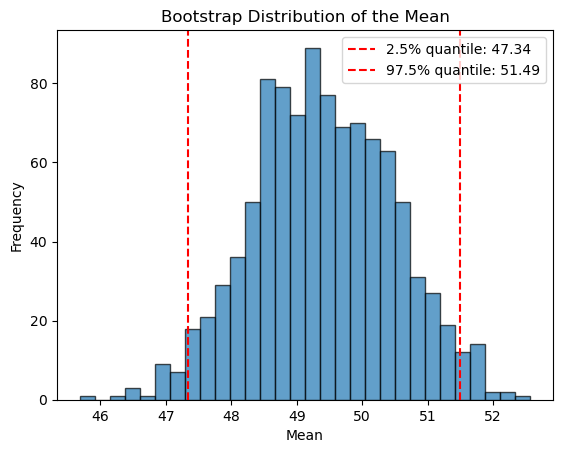

In [61]:
# Number of bootstrap iterations
n_iterations = 1000
boot_means = []

# Bootstrapping: resample with replacement and compute the mean of each sample
for _ in range(n_iterations):
    sample = df["data"].sample(frac=1, replace=True)
    boot_means.append(sample.mean())

# Convert the bootstrapped means to a pandas Series
boot_means = pd.Series(boot_means)

# 95% confidence interval from the quantiles of the bootstrap distribution
ci_lower = boot_means.quantile(0.025)
ci_upper = boot_means.quantile(0.975)

print("Bootstrap Mean Estimate:", boot_means.mean())
print("95% Confidence Interval: [{:.2f}, {:.2f}]".format(ci_lower, ci_upper))

# Plot the distribution of the bootstrapped means
plt.hist(boot_means, bins=30, edgecolor="k", alpha=0.7)
plt.axvline(x=ci_lower, color="red", linestyle="--", label=f"2.5% quantile: {ci_lower:.2f}")
plt.axvline(x=ci_upper, color="red", linestyle="--", label=f"97.5% quantile: {ci_upper:.2f}")
plt.xlabel("Mean")
plt.ylabel("Frequency")
plt.title("Bootstrap Distribution of the Mean")
plt.legend()
plt.show()